# Mandi Project - Phase 1: Exploratory Data Analysis

**Dataset:** `data/processed/mandi_dataset.csv` (v3: daily wholesale prices in PKR per 100 kg for 5 crops x 5 Punjab cities, merged with Open-Meteo weather; 1-2 day gaps forward-filled and flagged). Potato and Garlic have two AMIS series each (`variant`); this EDA uses Potato Fresh and Garlic (Local) as the main series, see section 1.

**How to use:** run the cells top to bottom (Run All). Every figure is saved in `eda_outputs/figures/` and every table in `eda_outputs/tables/`.

Install once if needed: `pip install pandas numpy matplotlib seaborn`

In [1]:
import warnings, calendar
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data").exists():          # notebook is inside /notebooks -> go one level up
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed" / "mandi_dataset.csv"
WEATHER = ROOT / "data" / "raw" / "weather_raw.csv"
OUT = ROOT / "eda_outputs"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight")
    plt.show()

CROPS = ["Onion", "Tomato", "Potato", "Garlic", "Green Chilli"]
CITIES = ["Lahore", "Faisalabad", "Rawalpindi", "Multan", "Gujranwala"]
print("Project root:", ROOT)

Project root: /tmp/claude-0/-home-claude/f7b50cb3-ad62-555e-9e90-f135abfd02f9/scratchpad/mandi/v3/Mandi Phase1_v3


## 1. Load the data and first look

In [2]:
df_all = pd.read_csv(DATA, parse_dates=["date"]).sort_values(["crop", "city", "variant", "date"]).reset_index(drop=True)
df_all = df_all.rename(columns={"price_pkr_per_100kg": "price"})
df_all["year"] = df_all["date"].dt.year
# one series per crop/city: Potato Fresh and Garlic (Local) are the primary series; the backups are kept in df_all
PRIMARY = {"Potato": "Potato Fresh", "Garlic": "Garlic (Local)"}
df = df_all[df_all["crop"].map(PRIMARY).fillna(df_all["variant"]) == df_all["variant"]].reset_index(drop=True)
print(df.shape, "(primary series)  |  all variants:", df_all.shape)
display(df.head())
df.info()

(40520, 36) (primary series)  |  all variants: (49252, 36)


,date,city,crop,variant,price,quality_tier,is_filled,is_stale,pct_chg_1d,pct_chg_7d,...,day_of_year,is_ramadan,days_to_next_eid,days_since_last_eid,is_pre_eid_10d,future_chg_7d,spike_7d,spike_threshold,split,year
0,2022-01-01,Faisalabad,Garlic,Garlic (Local),12400.0,A,0,0,NaN,NaN,...,1,0,60,60,0,0.000,0.0,0.1747,train,2022
1,2022-01-02,Faisalabad,Garlic,Garlic (Local),12400.0,C,1,0,0.0,NaN,...,2,0,60,60,0,0.000,0.0,0.1747,train,2022
2,2022-01-03,Faisalabad,Garlic,Garlic (Local),12400.0,A,0,0,0.0,NaN,...,3,0,60,60,0,-0.004,0.0,0.1747,train,2022
3,2022-01-04,Faisalabad,Garlic,Garlic (Local),12400.0,A,0,0,0.0,NaN,...,4,0,60,60,0,0.000,0.0,0.1747,train,2022
4,2022-01-05,Faisalabad,Garlic,Garlic (Local),12400.0,A,0,0,0.0,NaN,...,5,0,60,60,0,0.000,0.0,0.1747,train,2022


<class 'pandas.DataFrame'>
RangeIndex: 40520 entries, 0 to 40519
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  40520 non-null  datetime64[us]
 1   city                  40520 non-null  str           
 2   crop                  40520 non-null  str           
 3   variant               40520 non-null  str           
 4   price                 40520 non-null  float64       
 5   quality_tier          40520 non-null  str           
 6   is_filled             40520 non-null  int64         
 7   is_stale              40520 non-null  int64         
 8   pct_chg_1d            40105 non-null  float64       
 9   pct_chg_7d            39282 non-null  float64       
 10  pct_chg_14d           38821 non-null  float64       
 11  roll7_mean            40145 non-null  float64       
 12  roll7_std_pct         40145 non-null  float64       
 13  vol_14d               39831

In [3]:
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
print("Rows:", len(df), "| cities:", df["city"].nunique(), "| crops:", df["crop"].nunique())
print("\nMissing values per column (lag/rolling features are empty at the start of each series, target at the end):")
print(df.isna().sum()[lambda s: s > 0])
print(f"\nRows filled from the previous day (1-2 day gaps): {df['is_filled'].mean():.1%}")
print(f"Rows inside a stale run (10+ identical prices):   {df['is_stale'].mean():.1%}")
print("Quality tiers (A real, B real but stale, C filled):", df["quality_tier"].value_counts(normalize=True).round(3).to_dict())
print("\nAll AMIS series (variants):")
display(df_all.groupby(["crop", "variant"]).agg(rows=("date", "size"), stale_pct=("is_stale", lambda s: round(100 * s.mean(), 1)),
                                                 first=("date", "min"), last=("date", "max")))

Date range: 2022-01-01 -> 2026-11-20
Rows: 40520 | cities: 5 | crops: 5

Missing values per column (lag/rolling features are empty at the start of each series, target at the end):
pct_chg_1d               415
pct_chg_7d              1238
pct_chg_14d             1699
roll7_mean               375
roll7_std_pct            375
vol_14d                  689
price_vs_city_median     373
rain_7d_mm               150
rain_14d_mm              324
temp_mean_7d_c           150
future_chg_7d           1238
spike_7d                1238
dtype: int64

Rows filled from the previous day (1-2 day gaps): 11.4%
Rows inside a stale run (10+ identical prices):   7.3%
Quality tiers (A real, B real but stale, C filled): {'A': 0.813, 'C': 0.114, 'B': 0.073}

All AMIS series (variants):


rows  stale_pct      first       last
crop         variant                                              
Garlic       Garlic (China)  6844       14.4 2022-01-01 2026-11-20
             Garlic (Local)  8005       17.6 2022-01-01 2026-11-20
Green Chilli Green Chilli    8522        2.8 2022-01-01 2026-11-20
Onion        Onion           8726        3.8 2022-01-01 2026-11-20
Potato       Potato Fresh    6584       13.6 2022-01-01 2026-11-20
             Potato Store    1888       19.0 2022-01-01 2026-11-20
Tomato       Tomato          8683        1.0 2022-01-01 2026-11-20

## 2. Data coverage - how complete is each crop/city series?

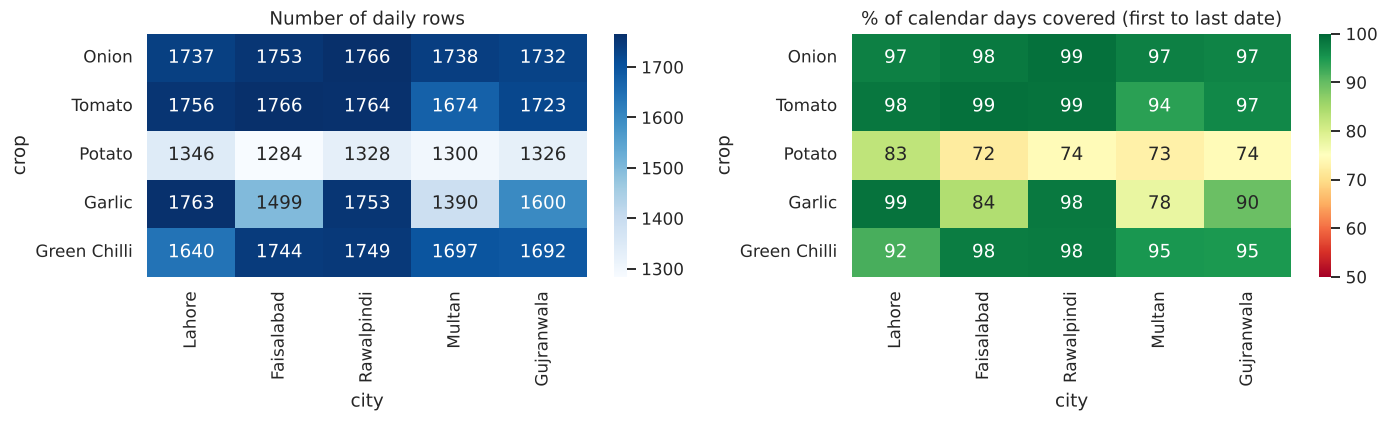

Series that stop before the end of the dataset:
crop    city  
Potato  Lahore    2026-06-19


In [4]:
cov = df.pivot_table(index="crop", columns="city", values="price", aggfunc="count").reindex(index=CROPS, columns=CITIES)
span = df.groupby(["crop", "city"])["date"].agg(lambda s: (s.max() - s.min()).days + 1).unstack().reindex(index=CROPS, columns=CITIES)
completeness = cov / span * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(cov, annot=True, fmt=".0f", cmap="Blues", ax=ax[0]); ax[0].set_title("Number of daily rows")
sns.heatmap(completeness, annot=True, fmt=".0f", cmap="RdYlGn", vmin=50, vmax=100, ax=ax[1])
ax[1].set_title("% of calendar days covered (first to last date)")
save(fig, "01_coverage")
completeness.round(1).to_csv(OUT / "tables" / "coverage_pct.csv")

last = df.groupby(["crop", "city"])["date"].max()
early = last[last < df["date"].max()]
print("Series that stop before the end of the dataset:")
print(early.dt.date.to_string() if len(early) else "none")

## 3. Summary statistics

In [5]:
by_crop = df.groupby("crop")["price"].agg(["count", "mean", "median", "std", "min", "max", "skew"]).reindex(CROPS).round(1)
by_city = df.groupby("city")["price"].agg(["count", "mean", "median", "std", "min", "max"]).reindex(CITIES).round(1)
median_tbl = df.pivot_table(index="crop", columns="city", values="price", aggfunc="median").reindex(index=CROPS, columns=CITIES).round(0)
yearly = df.pivot_table(index="year", columns="crop", values="price", aggfunc="mean")[CROPS].round(0)
for name, t in [("by_crop", by_crop), ("by_city", by_city), ("median_price_crop_city", median_tbl), ("mean_price_by_year", yearly)]:
    t.to_csv(OUT / "tables" / f"summary_{name}.csv")
    print(f"\n--- {name} ---")
    display(t)


--- by_crop ---


,count,mean,median,std,min,max,skew
crop,,,,,,,
Onion,8726,8997.7,7500.0,5003.5,1700.0,26750.0,0.7
Tomato,8683,8594.0,7800.0,4530.4,1500.0,27500.0,0.9
Potato,6584,4800.3,4600.0,2248.8,1000.0,12350.0,0.4
Garlic,8005,22708.6,19900.0,9754.8,9250.0,64700.0,1.4
Green Chilli,8522,10404.7,9250.0,5226.4,3300.0,42150.0,2.8



--- by_city ---


,count,mean,median,std,min,max
city,,,,,,
Lahore,8242,12472.1,10250.0,9282.0,1700.0,57000.0
Faisalabad,8046,10977.6,8750.0,7945.5,1500.0,57000.0
Rawalpindi,8360,11136.4,8450.0,8648.1,1600.0,58400.0
Multan,7799,9740.5,7700.0,6840.7,1000.0,38300.0
Gujranwala,8073,11768.1,9150.0,8763.4,1400.0,64700.0



--- median_price_crop_city ---


city,Lahore,Faisalabad,Rawalpindi,Multan,Gujranwala
crop,,,,,
Onion,8250.0,7600.0,7100.0,6750.0,7750.0
Tomato,8350.0,8200.0,7500.0,7200.0,7900.0
Potato,4800.0,4650.0,4250.0,4100.0,4900.0
Garlic,20500.0,19500.0,19750.0,17900.0,21350.0
Green Chilli,10750.0,8750.0,8850.0,7900.0,9300.0



--- mean_price_by_year ---


crop,Onion,Tomato,Potato,Garlic,Green Chilli
year,,,,,
2022,7729.0,9249.0,4452.0,18483.0,13693.0
2023,9264.0,6792.0,4854.0,23540.0,7993.0
2024,12582.0,9595.0,6106.0,32956.0,11769.0
2025,5911.0,6944.0,5565.0,22928.0,9198.0
2026,9480.0,10568.0,1842.0,15520.0,9121.0


## 4. Distributions (histograms)

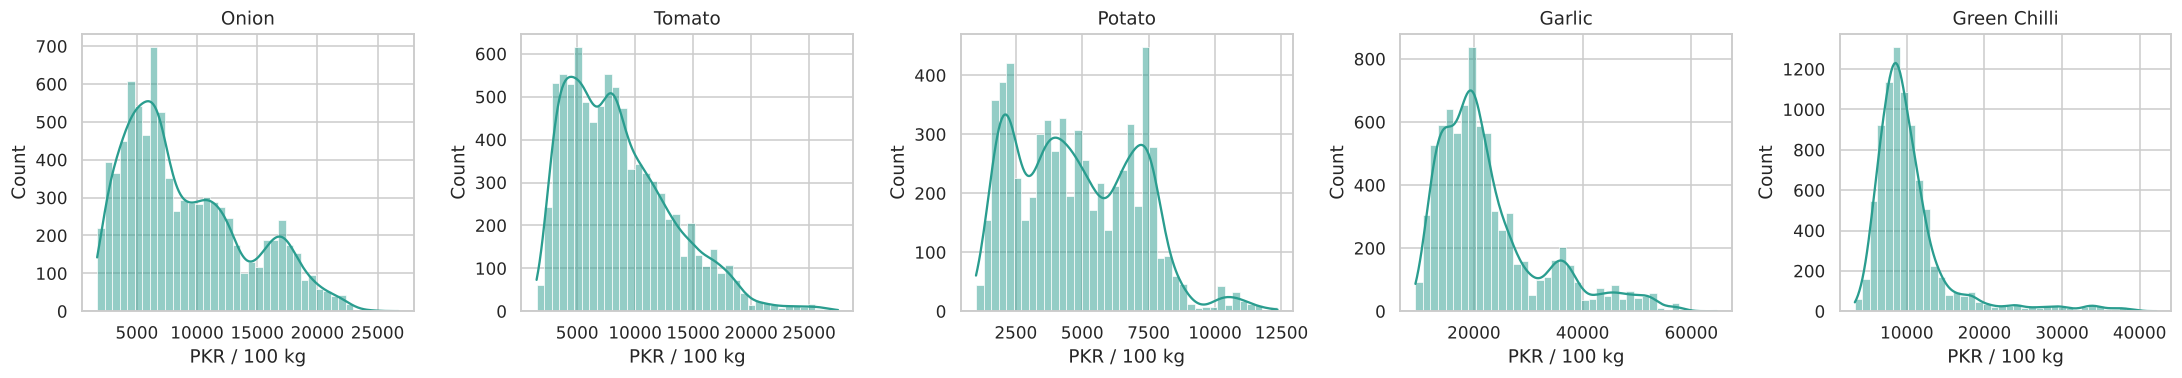

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, crop in zip(axes, CROPS):
    sns.histplot(df.loc[df["crop"] == crop, "price"], bins=40, kde=True, ax=ax, color="#2a9d8f")
    ax.set_title(crop); ax.set_xlabel("PKR / 100 kg")
save(fig, "02_histograms")

## 5. Boxplots - spread and outliers

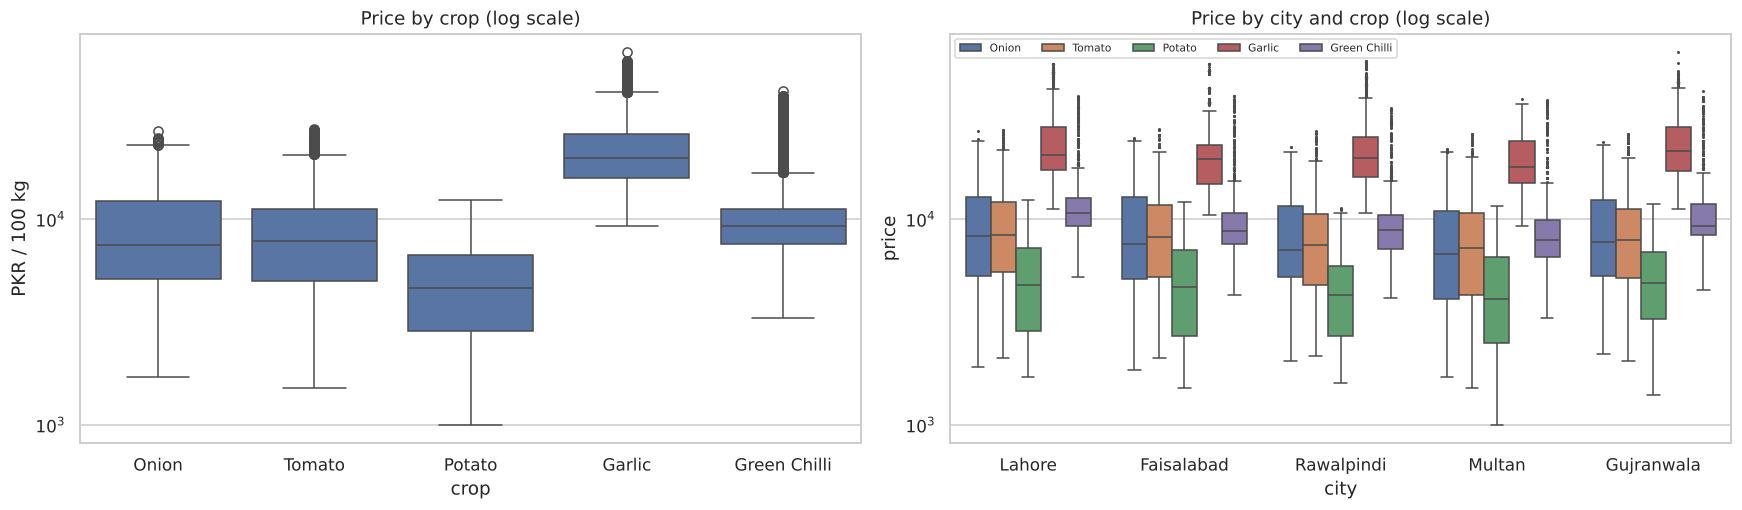

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.boxplot(data=df, x="crop", y="price", order=CROPS, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Price by crop (log scale)"); axes[0].set_ylabel("PKR / 100 kg")
sns.boxplot(data=df, x="city", y="price", hue="crop", order=CITIES, hue_order=CROPS, ax=axes[1], fliersize=1)
axes[1].set_yscale("log"); axes[1].set_title("Price by city and crop (log scale)"); axes[1].legend(fontsize=7, ncol=5)
save(fig, "03_boxplots")

## 6. Historical price charts (7-day average)

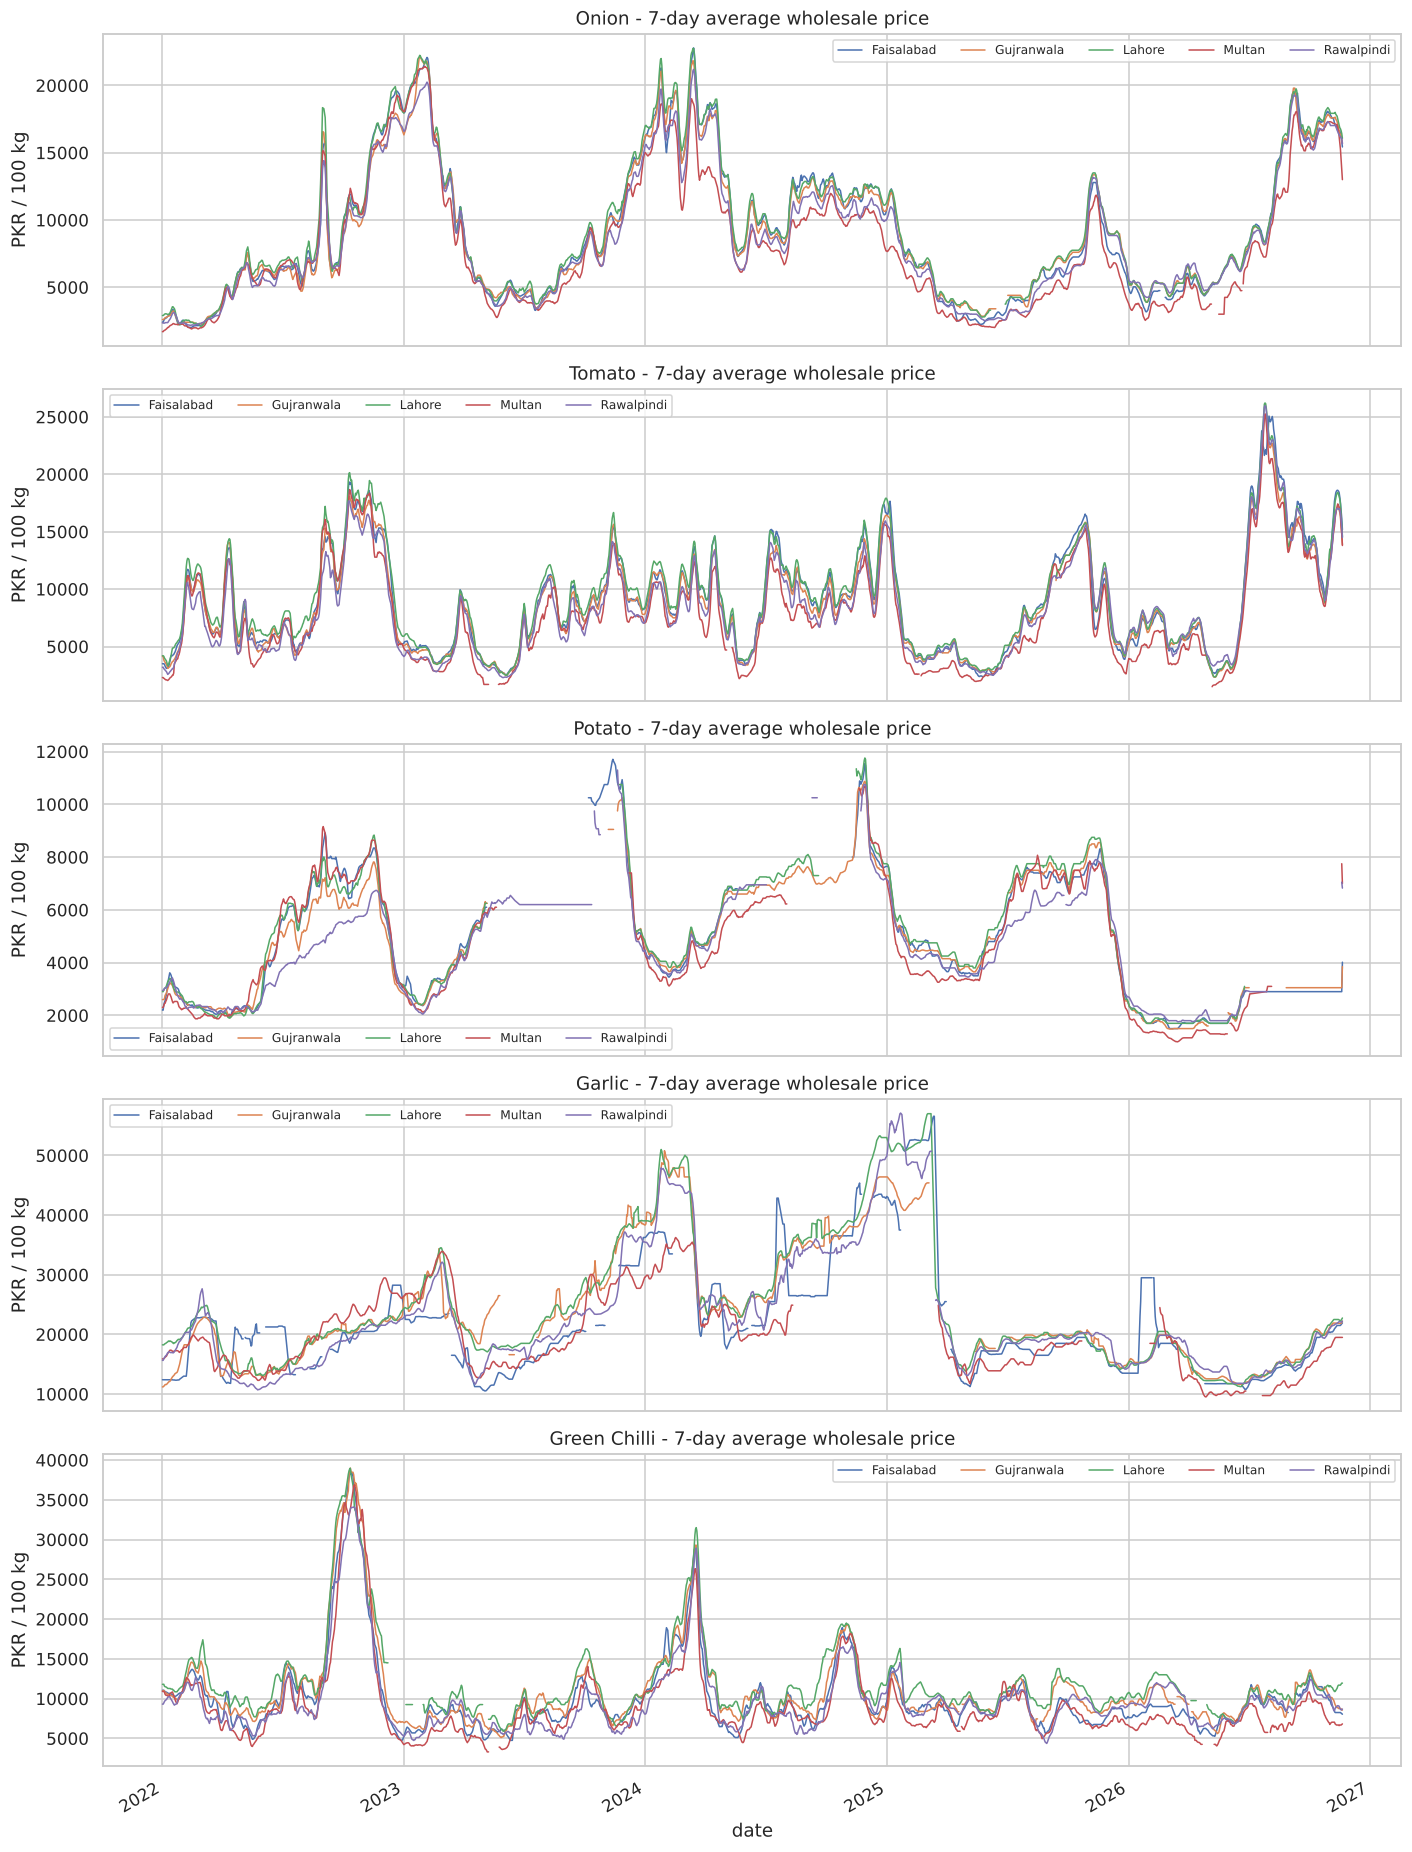

In [8]:
fig, axes = plt.subplots(5, 1, figsize=(13, 17), sharex=True)
for ax, crop in zip(axes, CROPS):
    p = df[df["crop"] == crop].pivot_table(index="date", columns="city", values="price")
    p.rolling(7, min_periods=1).mean().plot(ax=ax, linewidth=1)
    ax.set_title(f"{crop} - 7-day average wholesale price"); ax.set_ylabel("PKR / 100 kg"); ax.legend(ncol=5, fontsize=8)
save(fig, "04_price_history")

## 7. Bar plots - average price by city and by year

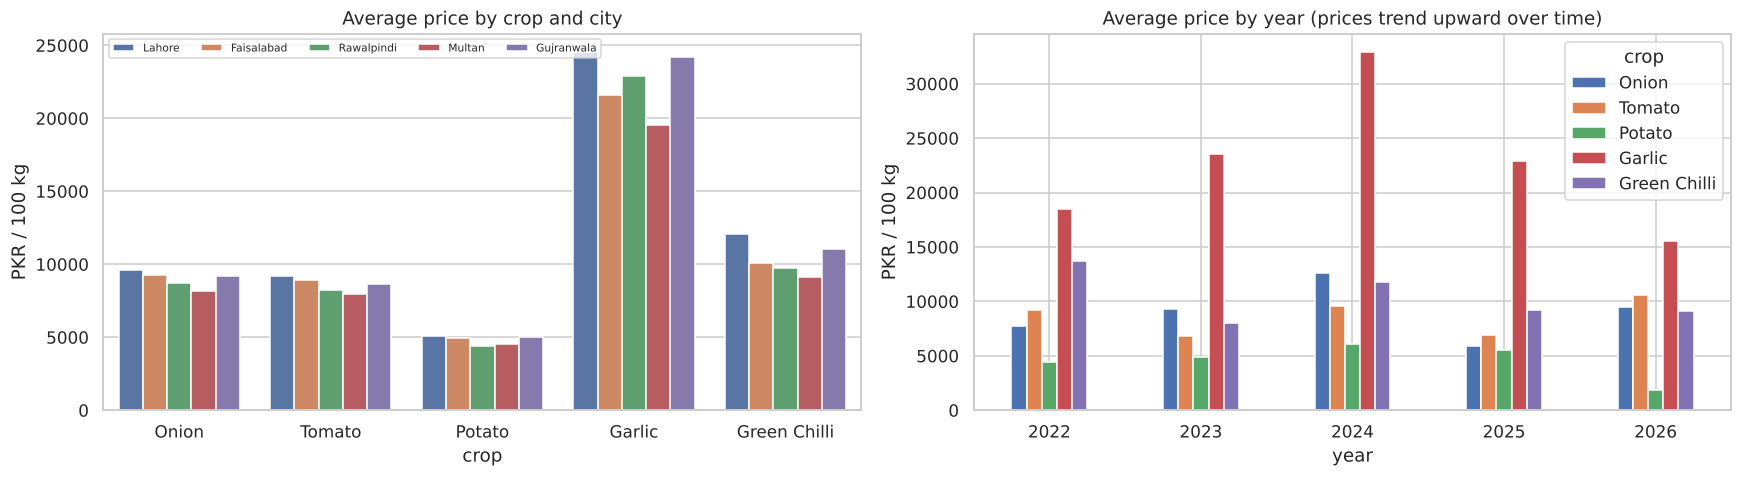

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.barplot(data=df, x="crop", y="price", hue="city", order=CROPS, hue_order=CITIES, errorbar=None, ax=axes[0])
axes[0].set_title("Average price by crop and city"); axes[0].set_ylabel("PKR / 100 kg"); axes[0].legend(fontsize=7, ncol=5)
yearly.plot(kind="bar", ax=axes[1]); axes[1].set_title("Average price by year (prices trend upward over time)")
axes[1].set_ylabel("PKR / 100 kg"); axes[1].tick_params(axis="x", rotation=0)
save(fig, "05_barplots")

## 8. Seasonal patterns
The *seasonal index* is each day's price divided by the average price of the same city, crop and **year**. Dividing by the yearly average removes the long-term price increase, so what remains is the pattern within the year (1.0 = normal, 1.2 = 20 % above the year's average). Note: 2026 has no December, so it is slightly biased.

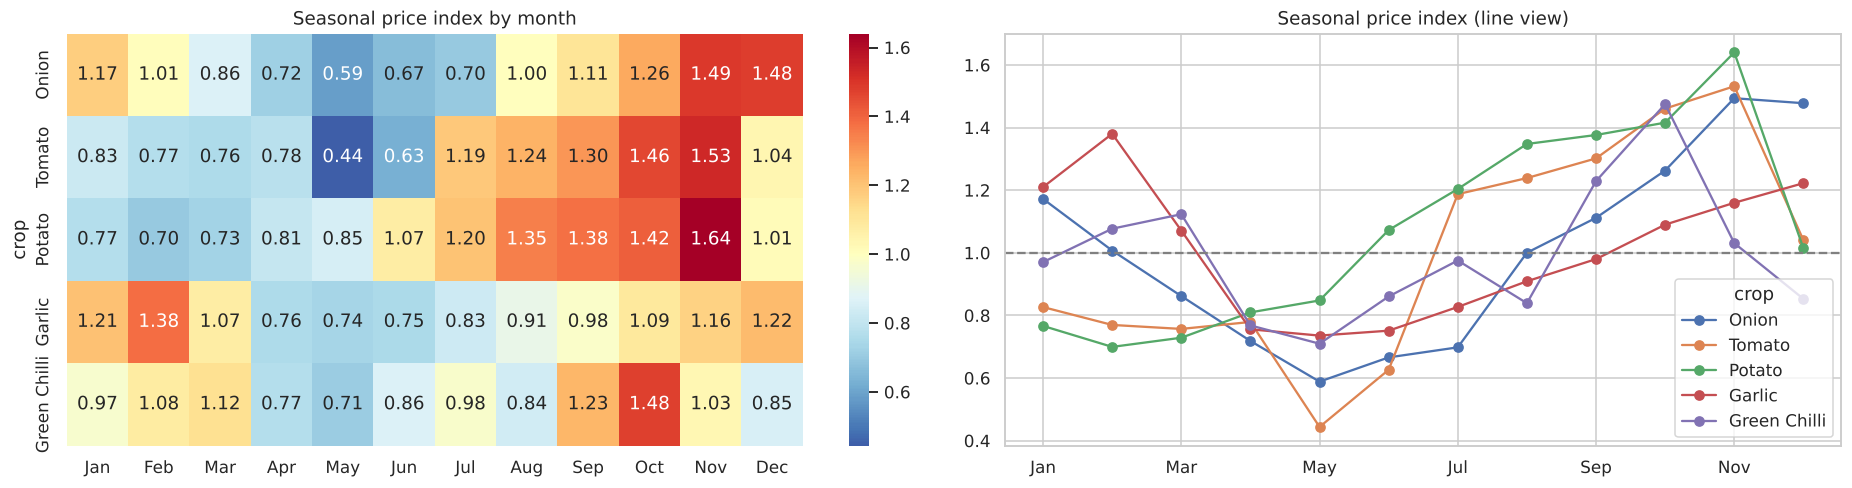

In [10]:
df["idx"] = df["price"] / df.groupby(["city", "crop", "year"])["price"].transform("mean")
season = df.pivot_table(index="crop", columns="month", values="idx", aggfunc="mean").reindex(CROPS)
season.columns = [calendar.month_abbr[m] for m in season.columns]
season.round(3).to_csv(OUT / "tables" / "seasonal_index.csv")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(season, annot=True, fmt=".2f", cmap="RdYlBu_r", center=1, ax=axes[0]); axes[0].set_title("Seasonal price index by month")
season.T.plot(ax=axes[1], marker="o"); axes[1].axhline(1, color="grey", ls="--"); axes[1].set_title("Seasonal price index (line view)")
save(fig, "06_seasonality")

## 9. Price variation - the 7-day change (basis of the "spike" target)
`chg7` = (price 7 days later - price today) / price today, in %. This is an **exploratory** version of the target Member 2 will build. The spike threshold here is `mean + 1.5 x std` of `chg7`, calculated **only on the first 70 % of dates** (training period) to avoid looking into the future.

Training cut-off date: 2025-05-21 | usable rows: 39282


,mean,std,threshold_%,first 70% (train),last 30%,all
crop,,,,,,
Onion,1.64,18.12,28.82,6.22,5.95,6.14
Tomato,3.55,28.07,45.65,7.30,6.84,7.16
Potato,0.24,11.76,17.88,6.14,4.86,5.77
Garlic,0.94,11.16,17.69,4.67,0.75,3.45
Green Chilli,2.04,19.64,31.49,7.74,2.41,6.16


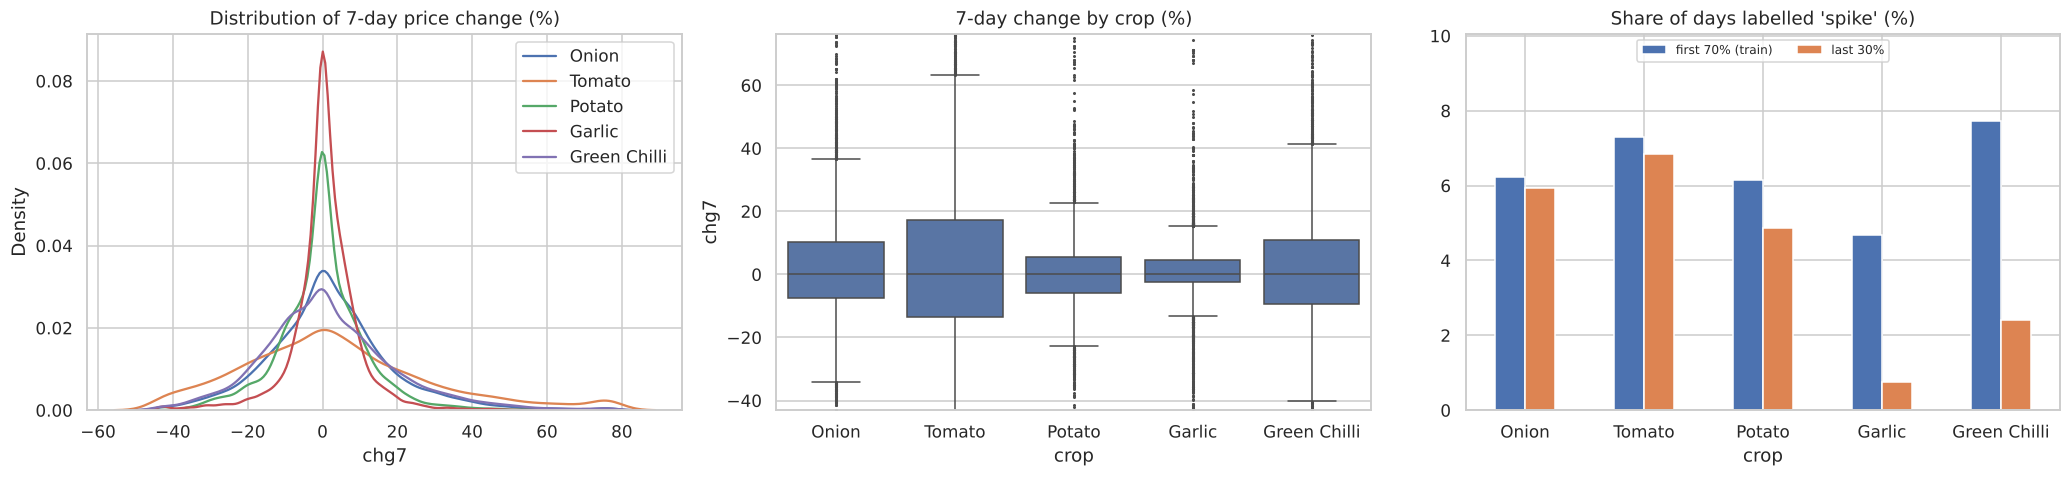

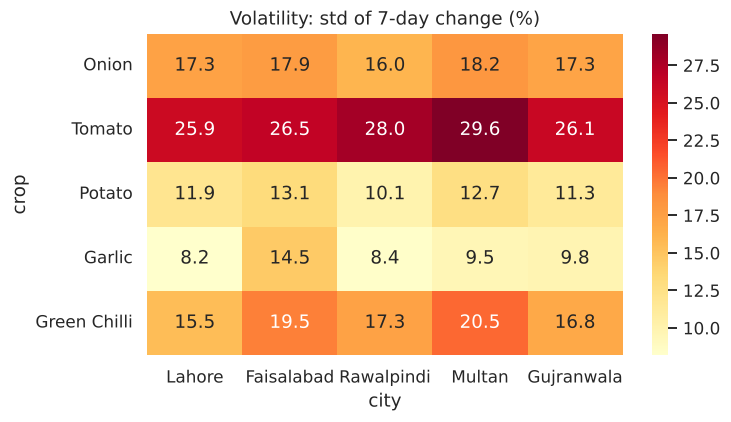

In [11]:
base = df[["city", "crop", "date", "price"]]
fut = base.rename(columns={"price": "price_next7"}).copy()
fut["date"] = fut["date"] - pd.Timedelta(days=7)
wk = base.merge(fut, on=["city", "crop", "date"])
wk["chg7"] = (wk["price_next7"] / wk["price"] - 1) * 100

cutoff = wk["date"].quantile(0.70)
thr = wk[wk["date"] <= cutoff].groupby("crop")["chg7"].agg(["mean", "std"])
thr["threshold_%"] = thr["mean"] + 1.5 * thr["std"]
wk = wk.merge(thr[["threshold_%"]], left_on="crop", right_index=True)
wk["spike"] = (wk["chg7"] > wk["threshold_%"]).astype(int)
wk["period"] = np.where(wk["date"] <= cutoff, "first 70% (train)", "last 30%")
print("Training cut-off date:", cutoff.date(), "| usable rows:", len(wk))

spike_tbl = wk.pivot_table(index="crop", columns="period", values="spike", aggfunc="mean").reindex(CROPS) * 100
spike_tbl["all"] = wk.groupby("crop")["spike"].mean().reindex(CROPS) * 100
summary9 = thr.join(spike_tbl).reindex(CROPS).round(2)
summary9.to_csv(OUT / "tables" / "weekly_change_and_spike_rate.csv")
display(summary9)

lo, hi = wk["chg7"].quantile([0.005, 0.995])          # plot limits: ignore the most extreme 1 % of days
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for crop in CROPS:
    sns.kdeplot(wk.loc[wk["crop"] == crop, "chg7"].clip(lo, hi), ax=axes[0], label=crop)
axes[0].set_title("Distribution of 7-day price change (%)"); axes[0].legend()
sns.boxplot(data=wk, x="crop", y="chg7", order=CROPS, ax=axes[1], fliersize=1); axes[1].set_ylim(lo, hi)
axes[1].set_title("7-day change by crop (%)")
spike_tbl[["first 70% (train)", "last 30%"]].plot(kind="bar", ax=axes[2]); axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(loc="upper center", ncol=2, fontsize=8); axes[2].set_ylim(0, spike_tbl[["first 70% (train)", "last 30%"]].max().max() * 1.3)
axes[2].set_title("Share of days labelled 'spike' (%)")
save(fig, "07_weekly_change")

vol = wk.pivot_table(index="crop", columns="city", values="chg7", aggfunc="std").reindex(index=CROPS, columns=CITIES)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(vol, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax); ax.set_title("Volatility: std of 7-day change (%)")
save(fig, "08_volatility_heatmap")

## 10. Weather and prices
Rainfall/temperature are taken from the full daily Open-Meteo file and summed over the 7 and 14 days **before** each day, so no future information is used.

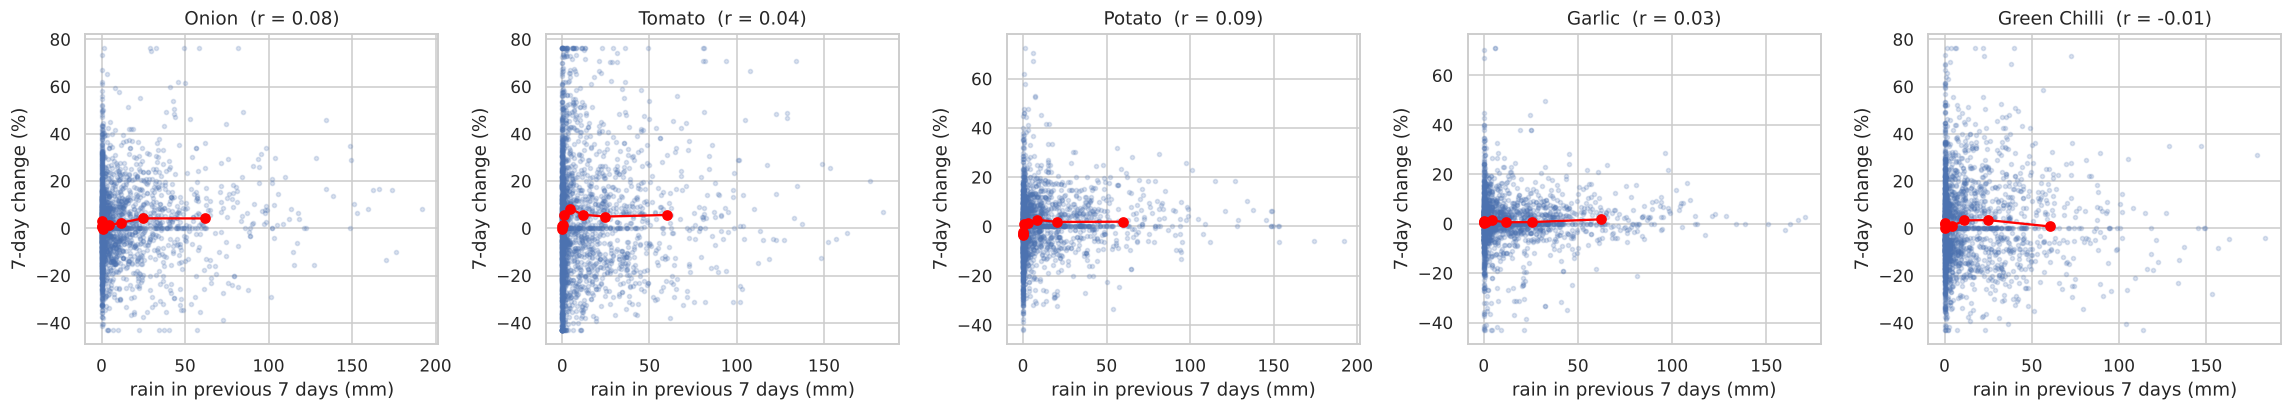

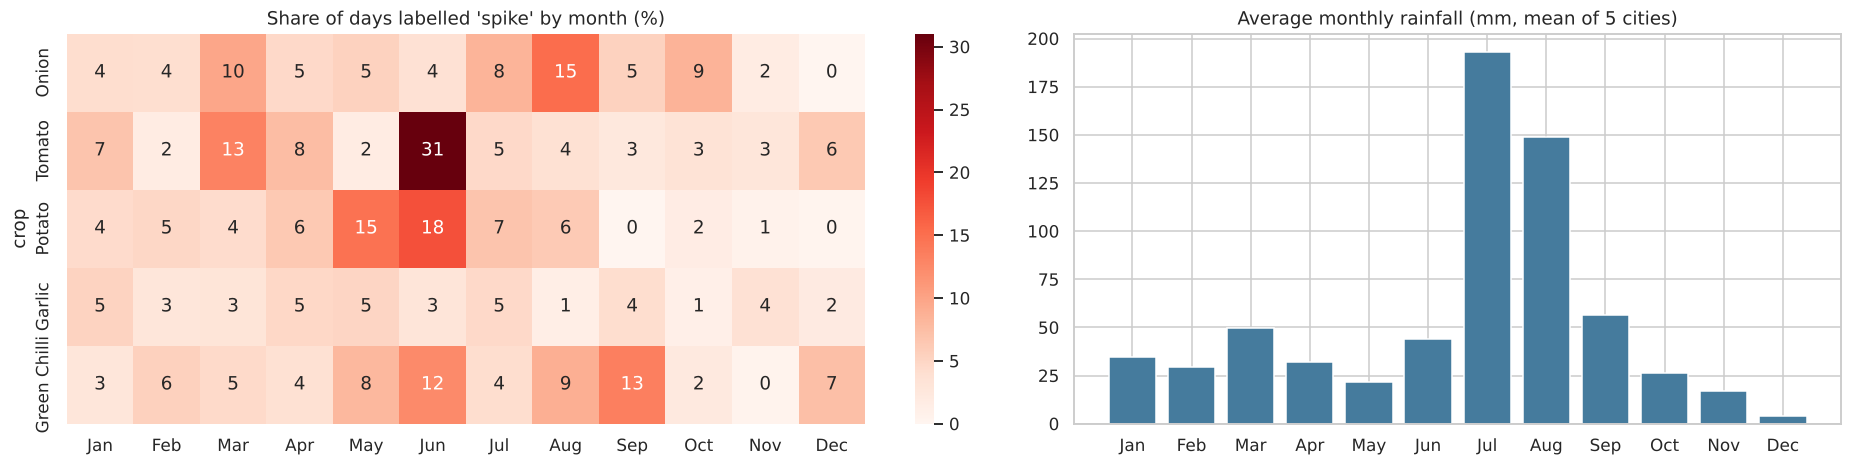

,rain_7d,rain_14d,temp_mean_c
Onion,0.080,0.053,0.123
Tomato,0.042,0.031,0.107
Potato,0.090,0.107,0.326
Garlic,0.033,0.017,0.015
Green Chilli,-0.009,0.004,0.074


In [12]:
wx = pd.read_csv(WEATHER, parse_dates=["date"]).sort_values(["city", "date"])
wx["rain_7d"] = wx.groupby("city")["precipitation_sum"].transform(lambda s: s.rolling(7, min_periods=7).sum())
wx["rain_14d"] = wx.groupby("city")["precipitation_sum"].transform(lambda s: s.rolling(14, min_periods=14).sum())
wk = wk.merge(wx[["city", "date", "rain_7d", "rain_14d"]], on=["city", "date"], how="left")
wk = wk.merge(df[["city", "crop", "date", "temp_mean_c", "month"]], on=["city", "crop", "date"], how="left")

corr = pd.DataFrame({crop: {c: wk.loc[wk["crop"] == crop, "chg7"].corr(wk.loc[wk["crop"] == crop, c])
                            for c in ["rain_7d", "rain_14d", "temp_mean_c"]} for crop in CROPS}).T
corr.round(3).to_csv(OUT / "tables" / "corr_weather_vs_chg7.csv")

fig, axes = plt.subplots(1, 5, figsize=(21, 3.9))
for ax, crop in zip(axes, CROPS):
    g = wk[wk["crop"] == crop].dropna(subset=["rain_7d", "chg7"]).copy()
    s = g.sample(min(len(g), 2500), random_state=0)
    ax.scatter(s["rain_7d"], s["chg7"].clip(lo, hi), s=7, alpha=0.2)
    g["bin"] = pd.qcut(g["rain_7d"].rank(method="first"), 8, labels=False)
    m = g.groupby("bin")[["rain_7d", "chg7"]].mean()
    ax.plot(m["rain_7d"], m["chg7"], color="red", marker="o", label="binned mean")
    ax.set_title(f"{crop}  (r = {corr.loc[crop, 'rain_7d']:.2f})"); ax.set_xlabel("rain in previous 7 days (mm)"); ax.set_ylabel("7-day change (%)")
save(fig, "09_rain_vs_change")

monthly_spike = wk.pivot_table(index="crop", columns="month", values="spike", aggfunc="mean").reindex(CROPS) * 100
monthly_spike.columns = [calendar.month_abbr[m] for m in monthly_spike.columns]
monthly_rain = wx.assign(month=wx["date"].dt.month).groupby("month")["precipitation_sum"].sum() / wx["date"].dt.year.nunique() / wx["city"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(monthly_spike, annot=True, fmt=".0f", cmap="Reds", ax=axes[0]); axes[0].set_title("Share of days labelled 'spike' by month (%)")
axes[1].bar([calendar.month_abbr[m] for m in monthly_rain.index], monthly_rain.values, color="#457b9d")
axes[1].set_title("Average monthly rainfall (mm, mean of 5 cities)")
save(fig, "10_spikes_and_rain_by_month")
display(corr.round(3))

## 11. Key findings (generated from the data)

In [13]:
vol_crop = wk.groupby("crop")["chg7"].std().sort_values(ascending=False)
peak, trough = season.idxmax(axis=1), season.idxmin(axis=1)
best_w = corr.abs().stack().sort_values(ascending=False)
lines = [
    f"1. Most volatile crop (std of 7-day change): {vol_crop.index[0]} ({vol_crop.iloc[0]:.1f} %); least volatile: {vol_crop.index[-1]} ({vol_crop.iloc[-1]:.1f} %).",
    f"2. Share of days labelled 'spike' overall: " + ", ".join(f"{c} {spike_tbl.loc[c, 'all']:.1f}%" for c in CROPS) + ".",
    "3. Seasonal peak / low month of the price index: " + "; ".join(f"{c} {peak[c]}/{trough[c]}" for c in CROPS) + ".",
    f"4. Strongest weather link with the 7-day change: {best_w.index[0][0]} vs {best_w.index[0][1]} (|r| = {best_w.iloc[0]:.2f}). "
    + ("Weather alone is a weak predictor (|r| < 0.2) - use it together with price features." if best_w.iloc[0] < 0.2 else "A noticeable relationship."),
    f"5. Price level rises year over year (mean price by year in table above) -> percentage-change features are safer than raw price levels.",
    f"6. {df['is_filled'].mean():.1%} of rows are forward-filled (Sundays/short holidays) and {df['is_stale'].mean():.1%} sit in stale runs (10+ identical prices); backup series are kept separate (column variant).",
]
if len(early):
    lines.append("7. Series that stop early: " + ", ".join(f"{c}/{ci} (ends {d.date()})" for (c, ci), d in early.items()) + ".")
print("\n".join(lines))
(OUT / "tables" / "key_findings.txt").write_text("\n".join(lines), encoding="utf-8")

1. Most volatile crop (std of 7-day change): Tomato (27.2 %); least volatile: Garlic (10.2 %).
2. Share of days labelled 'spike' overall: Onion 6.1%, Tomato 7.2%, Potato 5.8%, Garlic 3.5%, Green Chilli 6.2%.
3. Seasonal peak / low month of the price index: Onion Nov/May; Tomato Nov/May; Potato Nov/Feb; Garlic Feb/May; Green Chilli Oct/May.
4. Strongest weather link with the 7-day change: Potato vs temp_mean_c (|r| = 0.33). A noticeable relationship.
5. Price level rises year over year (mean price by year in table above) -> percentage-change features are safer than raw price levels.
6. 11.4% of rows are forward-filled (Sundays/short holidays) and 7.3% sit in stale runs (10+ identical prices); backup series are kept separate (column variant).
7. Series that stop early: Potato/Lahore (ends 2026-06-19).


810

## 12. Notes for the team (edit/extend with your own observations)

**Facts about the data to keep in mind in Phase 2**
- Only **one price per day** exists (AMIS "Price Trends" report). Min/max prices are not available, so a "daily price spread" feature cannot be built from this dataset; use the 7-day price range (`roll7_std_pct`) instead.
- `mandi_dataset.csv` already contains the features, the 7-day-ahead target (`future_chg_7d`), the spike label (`spike_7d`, threshold from the first 70 % of dates only) and a date-based `split` column. `future_chg_7d` must never be used as a feature.
- Rows with `is_filled = 1` repeat the previous trading day's price (1-2 day gaps). `mandi_observed_v3.csv` is the same data without them. `quality_tier`: A real, B real but stale, C filled.
- Potato and Garlic have two AMIS series each (`variant`). They are **not** spliced together any more: pick one variant per crop (Potato Fresh, Garlic (Local)) or model them separately.
- Gaps longer than 2 days are not filled. Lags and rolling windows were computed by calendar date.
- Some series have real data gaps/ends (see section 2), especially Potato in several cities.
- Prices rise over the years, so percentage changes generalise better than absolute prices.

**Your own observations**
- (write here)

In [14]:
print("Saved figures:")
for f in sorted((OUT / "figures").glob("*.png")):
    print("  ", f.name)
print("Saved tables:")
for f in sorted((OUT / "tables").glob("*")):
    print("  ", f.name)

Saved figures:
   01_coverage.png
   02_histograms.png
   03_boxplots.png
   04_price_history.png
   05_barplots.png
   06_seasonality.png
   07_weekly_change.png
   08_volatility_heatmap.png
   09_rain_vs_change.png
   10_spikes_and_rain_by_month.png
Saved tables:
   corr_weather_vs_chg7.csv
   coverage_pct.csv
   key_findings.txt
   seasonal_index.csv
   summary_by_city.csv
   summary_by_crop.csv
   summary_mean_price_by_year.csv
   summary_median_price_crop_city.csv
   weekly_change_and_spike_rate.csv
